In [12]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, LSTM
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping

In [13]:
TEXTE = "../data-sources/victor-hugo-texts.txt"

In [14]:
with open(TEXTE, 'r', encoding='utf-8') as f:
    texts = [line.strip() for line in f if line.strip()]
print(f"Exemple de texte : {texts[42]}")

Exemple de texte : Mon âme aux mille voix, que le Dieu que j'adore Mit au centre de tout comme un écho sonore !


In [15]:
vocab_size = 1800
window_size = 6

tokenizer = Tokenizer(num_words=vocab_size)
tokenizer.fit_on_texts(texts)
sequences = tokenizer.texts_to_sequences(texts)

In [16]:
X, y = [], []

for seq in sequences:
    for i in range(1, len(seq)):
        start_index = max(0, i - window_size) # prendre au plus les 3 derniers mots
        X.append(seq[start_index:i])
        y.append(seq[i])

X = pad_sequences(X, maxlen=window_size, padding='pre')
y = np.array(y)

print(f"X shape : {X.shape}, y shape : {y.shape}")

X shape : (12888, 6), y shape : (12888,)


In [17]:
embedding_dim = 16
model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=embedding_dim),
    LSTM(64),
    Dense(vocab_size, activation='softmax')
])

model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [18]:
early_stop = EarlyStopping(monitor='loss', patience=10, restore_best_weights=True)

history = model.fit(
    X, y,
    epochs=500,
    batch_size=32,
    callbacks=[early_stop]
)

Epoch 1/500


403/403 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.0303 - loss: 6.6053
Epoch 2/500
403/403 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.0326 - loss: 6.2396
Epoch 3/500
403/403 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.0303 - loss: 6.1600
Epoch 4/500
403/403 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.0331 - loss: 6.1027
Epoch 5/500
403/403 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.0365 - loss: 6.0513
Epoch 6/500
403/403 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.0391 - loss: 5.9927
Epoch 7/500
403/403 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.0438 - loss: 5.9205
Epoch 8/500
403/403 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.0479 - loss: 5.8440
Epoch 9/500
403/403 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.0515 - loss: 5.7672
Epoch 10/500
403/403 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.0533 - loss: 5.6903
Epoch 11/500
403/403 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.0589 - loss: 5.6135
Epoch 12/500
403/403 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step

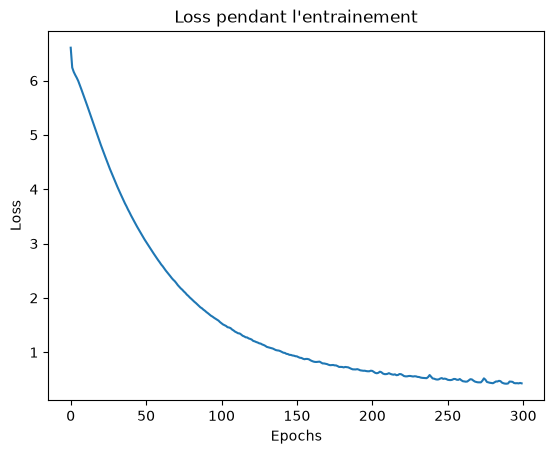

In [19]:
plt.plot(history.history['loss'])
plt.title('Loss pendant l\'entrainement')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.show()

In [20]:
def generate_text(start_text, num_words=50, temperature=0.8):
    text = start_text
    for _ in range(num_words):
        # même format qu'à l'entrainement : les 3 derniers mots seulement
        tokens = tokenizer.texts_to_sequences([text])[0][-window_size:]
        tokens = pad_sequences([tokens], maxlen=window_size, padding="pre")
        probs = model.predict(tokens, verbose=0)[0]

        # tirage au sort pondéré (température < 1 : plus sur, > 1 plus varié)
        probs = np.exp(np.log(probs + 1e-9) / temperature)
        probs /= probs.sum()
        index = np.random.choice(len(probs), p=probs)

        word = tokenizer.index_word.get(index)
        if word is not None: # l'indice 0 sert au bourrage, pas un mot TODO apocompris
            text += " " + word
    return text

In [22]:
print(generate_text("Le poête", num_words=50, temperature=0.2))

Le poête vent qui vient à travers la montagne me rendra fou dans l'onde par leurs l'oreille y des coeurs sans voir les être d'où mes tous nous a notre lit tu à mots rien n'est un bossu sous les touffes d'orties vous qui enfants pouvoir le milieu et de l'ombre soit


# Window_size=6

> Le poête vent qui vient à travers la montagne me rendra fou dans l'onde par leurs l'oreille y des coeurs sans voir les être d'où mes tous nous a notre lit tu à mots rien n'est un bossu sous les touffes d'orties vous qui enfants pouvoir le milieu et de l'ombre soit

Le rendu est meilleur avec un window_size plus grand, mais plus long à calculer et à entraîner